## Описание проекта

В качестве тестового задания исследуйте данные онлайн-магазина подарков. Магазин зачастую отправляет товары по почте, работает как с оптовыми, так и с розничными покупателями. 
Вы должны применить Python для анализа данных и показать, что можете самостоятельно решить задачу по исследованию данных, сегментации клиентов и проверке статистических гипотез.

# Получение, осмотр и объединение данных

In [5]:
# Импортируем нужные библиотеки


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import mannwhitneyu

In [6]:
df_gift = pd.read_csv('/datasets/gift.csv')
df_entry = pd.read_csv("https://code.s3.yandex.net/python-for-analytics/gift_entry.csv", sep=";")

#Основная информация
df_gift.describe()
df_gift.info()
df_entry.info()


# Произведем предобработку данных

# Привелем дату к типу datetime
df_gift['entry_date'] = pd.to_datetime(df_gift['entry_date'])


# Удалим полные дубликаты
df_gift = df_gift.drop_duplicates()
df_entry = df_entry.drop_duplicates(subset=['entry_id'])


df = df_gift



neg_price = df[df['price'] <= 0]
neg_quantity = df[df['quantity'] <= 0]
neg_customer = df[df['customer_id'] <= 0]
neg_name_clust = df[df['name_clust'] == 0]
neg_country_id = df[df['country_id'] == 0]



print(f"\nЗаписей с неположительной ценой: {len(neg_price):,} ({len(neg_price)/len(df)*100:.2f}%)")
print(f"Записей с неположительным количеством: {len(neg_quantity):,} ({len(neg_quantity)/len(df)*100:.2f}%)")
print(f"Записей с неположительным customer_id: {len(neg_customer):,} ({len(neg_customer)/len(df)*100:.2f}%)")
print(f"Записей с нулевым name_clust: {len(neg_name_clust):,} ({len(neg_name_clust)/len(df)*100:.2f}%)")
print(f"Записей с нулевым country_id : {len(neg_country_id):,} ({len(neg_country_id)/len(df)*100:.2f}%)")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 356940 entries, 0 to 356939
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   entry_date   356940 non-null  object
 1   order_id     356940 non-null  int64 
 2   customer_id  356940 non-null  int64 
 3   quantity     356940 non-null  int64 
 4   price        356940 non-null  int64 
 5   name_clust   356940 non-null  int64 
 6   entry_id     356940 non-null  int64 
 7   country_id   356940 non-null  int64 
dtypes: int64(7), object(1)
memory usage: 21.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2917 entries, 0 to 2916
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   entry_id  2917 non-null   int64 
 1   entry     2916 non-null   object
dtypes: int64(1), object(1)
memory usage: 45.7+ KB

Записей с неположительной ценой: 2,073 (0.59%)
Записей с неположительным количеством: 1,037 (0.29%)
Записей с

 Записей с неположительной ценой и неположительным количеством меньше 0.6%, так что сильно они не повлияют, и их можно
 не рассматривать при анализе
 Неположительный customer_id составляет примерно четверть, лучше эти значения заменить на undefined


In [7]:
df = df[(df['price'] > 0) & (df['quantity'] > 0)].copy()
df.loc[df['customer_id'] <= 0, 'customer_id'] = 'undefined'

#Записей с нулевыми name_clust и name_country меньше одного процента, так чо их можно не рассматривать при анализе
df = df[(df['name_clust'] > 0) & (df['country_id'] > 0)].copy()





neg_price = df[df['price'] <= 0]
neg_quantity = df[df['quantity'] <= 0]
# так как у нас теперь в customer_id есть undefined, то проверяем только неположительные значения
numeric_mask = pd.to_numeric(df['customer_id'], errors='coerce') <= 0
neg_customer = df[numeric_mask]
neg_name_clust = df[df['name_clust'] == 0]
neg_country_id = df[df['country_id'] == 0]

print(f"\nЗаписей с неположительной ценой: {len(neg_price):,} ({len(neg_price)/len(df)*100:.2f}%)")
print(f"Записей с неположительным количеством: {len(neg_quantity):,} ({len(neg_quantity)/len(df)*100:.2f}%)")
print(f"Записей с неположительным customer_id: {len(neg_customer):,} ({len(neg_customer)/len(df)*100:.2f}%)")
print(f"Записей с нулевым name_clust: {len(neg_name_clust):,} ({len(neg_name_clust)/len(df)*100:.2f}%)")
print(f"Записей с нулевым country_id : {len(neg_country_id):,} ({len(neg_country_id)/len(df)*100:.2f}%)")

df.describe()

# Проверим сколько процентов данных было отфильтровано 
print("Процент отсеянных данных:", round((1 - df.shape[0]/df_gift.shape[0]) * 100 ,2)) #порядка 1.13% - некритично


Записей с неположительной ценой: 0 (0.00%)
Записей с неположительным количеством: 0 (0.00%)
Записей с неположительным customer_id: 0 (0.00%)
Записей с нулевым name_clust: 0 (0.00%)
Записей с нулевым country_id : 0 (0.00%)
Процент отсеянных данных: 1.13


Соеденим два датасета по entry_id с помощью left join, тк df_entry содержит текстовые описания (entry) для entry_id,
а основной таблицей, хранящей в себе основные сведения, транзакции и т.д. находятся в df_gift
(сейчас мы его уже переменовали в df)


In [26]:

df = df.merge(df_entry, on='entry_id', how='left')
df.describe()


,order_id,quantity,price,name_clust,entry_id,country_id
count,349384.000000,349384.000000,3.493840e+05,349384.000000,349384.000000,349384.000000
mean,26713.260859,10.364722,3.307025e+02,472.331446,1527.232220,26.797014
std,13378.663379,141.533301,2.717536e+03,256.687085,827.885515,4.844788
min,3031.000000,1.000000,6.000000e+00,1.000000,1.000000,1.000000
25%,14857.000000,1.000000,1.250000e+02,247.000000,900.000000,28.000000
50%,27438.000000,3.000000,2.080000e+02,450.000000,1562.000000,28.000000
75%,38530.000000,10.000000,4.130000e+02,704.000000,2223.000000,28.000000
max,48253.000000,80995.000000,1.354133e+06,929.000000,2916.000000,29.000000


# Предобработка и начало исследовательского анализа

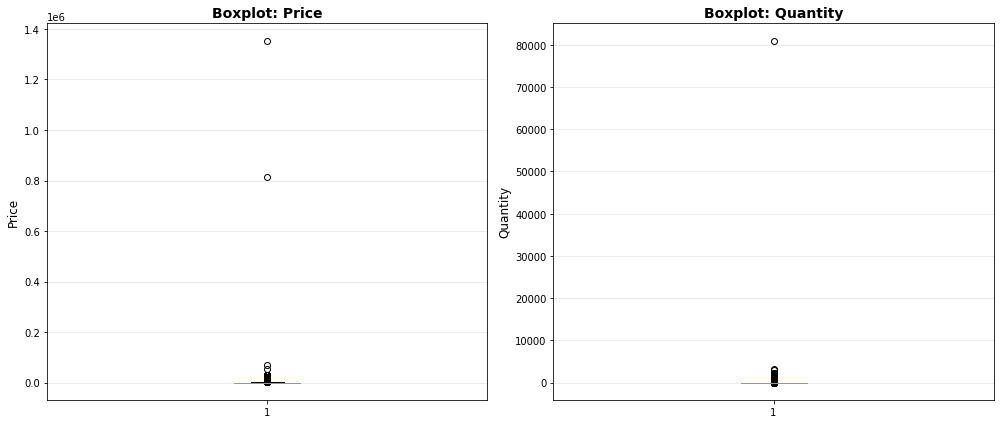

In [8]:
# Проанализируем отдельно price и quantity (выбросы смотрим при помощи "ящика с усами")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].boxplot(df['price'])
axes[0].set_title('Boxplot: Price', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

axes[1].boxplot(df['quantity'])
axes[1].set_title('Boxplot: Quantity', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Quantity', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

В данных наблюдается большое количество выбросов. Анализируя основную информацию, можно увидеть, что медиана цены и
количество составляют 208 и 3 соответственно, таким образом, лучше всего отсечь слишком высокие значения по 97 квантилю,
таким образом мы потеряем не более 6% от данных, что допустимо

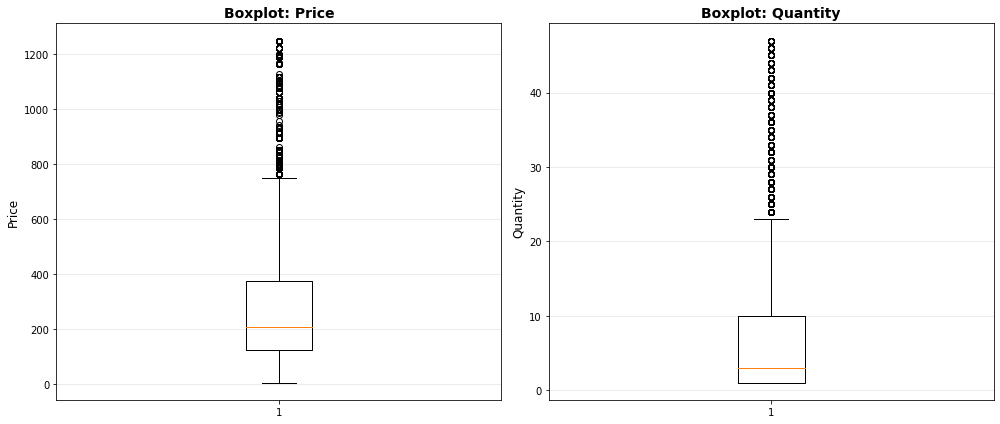

In [9]:
price_97 = df['price'].quantile(0.97)
quantity_97 = df['quantity'].quantile(0.97)
df = df.query('price < @price_97 and quantity < @quantity_97')
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].boxplot(df['price'])
axes[0].set_title('Boxplot: Price', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

axes[1].boxplot(df['quantity'])
axes[1].set_title('Boxplot: Quantity', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Quantity', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

###  Изучение столбцов 

Общее количество уникальных клиентов (undefined не рассматриваем (их порядка 25% от всех, тк нет возможности установить,
сколько заказов сделал каждый из них

In [10]:
unique_customers = df[df['customer_id'] != 'undefined']['customer_id'].nunique()
print("Количество уникальных покупателей: ", unique_customers)

# Рассчитываем выручку (quantity * price)
df['revenue'] = df['quantity'] * df['price']

# Рассмотрим кластеры по выручке
cluster_revenue = df.groupby('name_clust')['revenue'].agg(['sum', 'mean', 'count']).round(2)
cluster_revenue.columns = ['total_sum', 'avg_sum', 'count_orders']
cluster_revenue = cluster_revenue.sort_values('total_sum', ascending=False)
cluster_revenue['percentage'] = (cluster_revenue['total_sum'] / cluster_revenue['total_sum'].sum() * 100).round(2)

print("\n10 лучших кластеров по выручке")
print(cluster_revenue.head(10))

# Рассмотрим страны по выручке
country_revenue = df.groupby('country_id')['revenue'].agg(['sum', 'mean', 'count']).round(2)
country_revenue.columns = ['total_sum', 'avg_sum', 'count_orders']
country_revenue = country_revenue.sort_values('total_sum', ascending=False)
country_revenue['percentage'] = (country_revenue['total_sum'] / country_revenue['total_sum'].sum() * 100).round(2)

print("\n10 лучших стран по выручке")
print(country_revenue.head(10))
# 90 процентов заказов приходится на одну страну. Возможно, это основный рынок интернет-магазина'''

frequency = df[df['customer_id'] != 'undefined'].groupby('customer_id').size().sort_values()


# Распределение клиентов по количеству покупок
bins = [1, 2, 5, 10, 50, 100000]
labels = ['1 заказ', '2-5 заказов', '6-10 заказов', '11-50 заказов', '50+ заказов']
frequency = pd.cut(frequency, bins=bins, labels=labels, right = False)
distribution = frequency.value_counts().sort_index()
for label, count in distribution.items():
    print(f"  {label}: {count:,} клиентов ({count/len(frequency)*100:.1f}%)")


# Проанализируем данные по времени           
duration = (df['entry_date'].max() - df['entry_date'].min()).days + 1
print("\nКоличество дней всего: ", duration)

df['date'] = df['entry_date'].dt.date
daily_sales = df.groupby('date').size().reset_index(name='orders_count')
days_sales = daily_sales[daily_sales['orders_count'] > 0]
print("Количество дней c покупками: ", days_sales.shape[0])

df['month'] = df['entry_date'].dt.to_period('M')


# Дни с продажами по месяцам
days_with_sales_by_month = df.groupby('month')['date'].nunique().reset_index(name='days_with_sales')

# Все дни в каждом месяце
all_days_by_month = df.groupby('month').agg(
    total_days=('date', lambda x: (x.max() - x.min()).days + 1)
).reset_index()


# Объединяем и считаем дни без продаж
result = all_days_by_month.merge(days_with_sales_by_month, on='month', how='left')
result['days_without_sales'] = result['total_days'] - result['days_with_sales']
result['percentage'] = (result['days_with_sales'] / result['total_days'] * 100).round(2)

print("Дневные продажи по месяцам:",result)

# Удаляем данные за 2018 и 2019 год, тк они неполные
df = df[df['entry_date'].dt.year == 2019].copy()
df = df[df['month'] != '2019-12']


Количество уникальных покупателей:  4144

10 лучших кластеров по выручке
            total_sum   avg_sum  count_orders  percentage
name_clust                                               
427           9805206   1502.25          6527        2.41
415           7477208   1613.90          4633        1.84
87            6145090  10687.11           575        1.51
102           5477884   2525.53          2169        1.35
516           5469323   1332.68          4104        1.34
726           4458446   1929.23          2311        1.10
195           4264179   2722.98          1566        1.05
223           4129019   1294.36          3190        1.02
196           4049806   2660.84          1522        1.00
898           3934282   1359.46          2894        0.97

10 лучших стран по выручке
            total_sum  avg_sum  count_orders  percentage
country_id                                              
28          365182921  1191.71        306437       89.80
6            12009974  2011.38  

# Расчет метрик

Статистика по часам:    hour_block  orders_count
0      00-04             0
1      04-08           113
2      08-12         76011
3      12-16        159634
4      16-20         50275
5      20-24           446


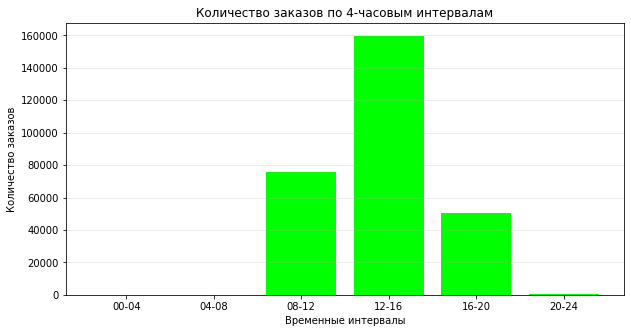

Статистика по дням недели:
  weekday  orders_count
1     Mon         42029
6     Tue         56971
5     Wed         35990
4     Thu         49488
0     Fri         55496
2     Sat         51039
3     Sun         52437


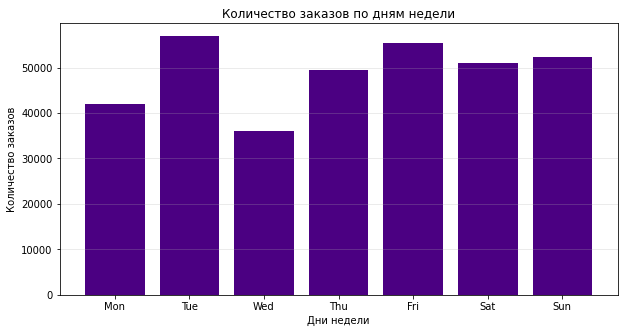

In [11]:
# Анализ количества покупок внутри дня
df['hour'] = df['entry_date'].dt.hour
# Разобьем на 6 интервалов по 4 часа каждый
bins = [0, 4, 8, 12, 16, 20, 24]
labels = ['00-04', '04-08', '08-12', '12-16', '16-20', '20-24']

df['hour_block'] = pd.cut(df['hour'], bins=bins, labels=labels, right = False)
block_stats = df.groupby('hour_block', observed=False).agg({'order_id': 'count'}).reset_index()
block_stats.columns = ['hour_block', 'orders_count']


print("Статистика по часам: ", block_stats)


plt.figure(figsize=(10, 5))
plt.bar(block_stats['hour_block'], block_stats['orders_count'], color='lime')
plt.title('Количество заказов по 4-часовым интервалам', fontsize=12)
plt.xlabel('Временные интервалы')
plt.ylabel('Количество заказов')
plt.grid(axis='y', alpha=0.3)
plt.show()



df['weekday'] = df['entry_date'].dt.dayofweek

weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
df['weekday_name'] = df['weekday'].map(lambda x: weekday_labels[x])

weekday_stats = df.groupby('weekday_name', observed=False).agg({'order_id': 'count'}).reset_index()
weekday_stats.columns = ['weekday', 'orders_count']

# Добавим вторник вручную, тк он не отображался иначе
tuesday_row = pd.DataFrame({'weekday': ['Tue'], 'orders_count': [56971]})
weekday_stats = pd.concat([weekday_stats, tuesday_row], ignore_index=True)

weekday_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday_stats['weekday'] = pd.Categorical(weekday_stats['weekday'], categories=weekday_order, ordered=True)
weekday_stats = weekday_stats.sort_values('weekday')

print("Статистика по дням недели:")
print(weekday_stats)

plt.figure(figsize=(10, 5))
plt.bar(weekday_stats['weekday'], weekday_stats['orders_count'], color='indigo')
plt.title('Количество заказов по дням недели', fontsize=12)
plt.xlabel('Дни недели')
plt.ylabel('Количество заказов')
plt.grid(axis='y', alpha=0.3)
plt.show()

Видно, что в течение недели есть просадка по количеству покупок в среду (возможно в это время идут технические работы на сайте), в остальные дни показатель примерно одинаков,
наибольшее кол-во наблюдается по пятницам. В течение суток основные продажи идут с 8 утра до 8 вечера, причем
пик наблюдается с 12 до 16 часов. Также есть небольшое количество покупателейс 20 до 24 часов, и почти никто не
покупает с полуночи до 8 утра, скорее всего это связано сбиологическими ритмами, то есть люди просто спят



Статистика по месяцам:
      month  avg_unique_customers_per_day  avg_revenue_per_customer_per_day
0   2019-01                         35.62                          22222.77
1   2019-02                         35.29                          20498.44
2   2019-03                         40.70                          20290.50
3   2019-04                         45.43                          20371.91
4   2019-05                         49.08                          21459.57
5   2019-06                         43.46                          20768.39
6   2019-07                         41.54                          20926.46
7   2019-08                         41.15                          22825.08
8   2019-09                         55.38                          25139.89
9   2019-10                         60.35                          25179.08
10  2019-11                         84.38                          22297.98


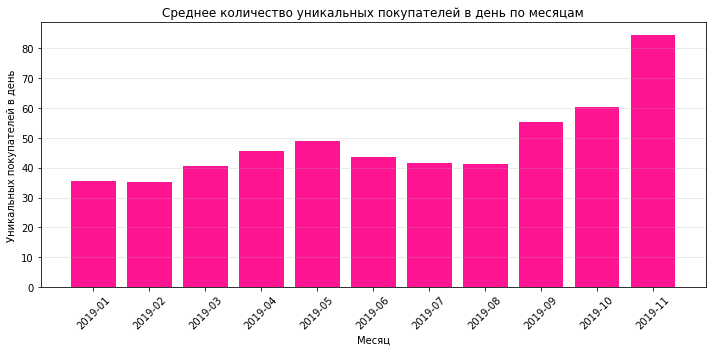

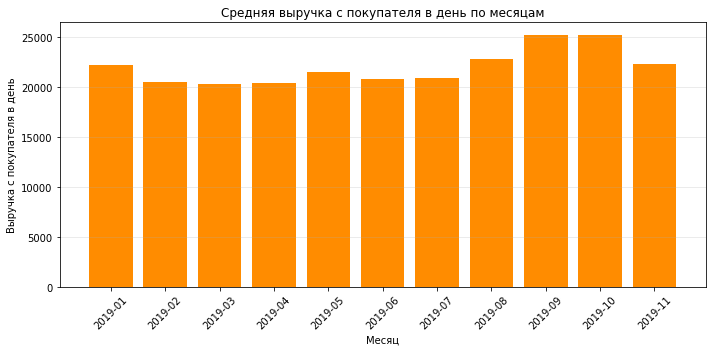

In [12]:
# Рассчитаем по месяцам среднюю выручку в день

# Берем только реальных клиентов
df_real = df[df['customer_id'] != 'undefined'].copy()

# Рассчитываем сумму стоимости каждой товарной позиции
df_real['total_value'] = df_real['quantity'] * df_real['price']

df_real['date'] = df_real['entry_date'].dt.date
df_real['month'] = df_real['entry_date'].dt.to_period('M')

# Группируем по дате 
daily_stats = df_real.groupby('date').agg({
    'total_value': 'sum',           
    'customer_id': 'nunique',
    'month': 'first'                
}).reset_index()

daily_stats.columns = ['date', 'daily_revenue', 'unique_customers_per_day', 'month']

# Создаем столбец с выручкой на клиента в день
daily_stats['revenue_per_customer_per_day'] = (daily_stats['daily_revenue'] / daily_stats['unique_customers_per_day']).round(2)

# 5. Группируем по месяцам 
monthly_stats = daily_stats.groupby('month').agg({
    'unique_customers_per_day': 'mean',
    'revenue_per_customer_per_day': 'mean'
}).round(2).reset_index()

monthly_stats.columns = ['month', 'avg_unique_customers_per_day', 'avg_revenue_per_customer_per_day']

print("Статистика по месяцам:")
print(monthly_stats)

# Количество уникальных покупателей в день по месяцам
plt.figure(figsize=(10, 5))
plt.bar(monthly_stats['month'].astype(str), monthly_stats['avg_unique_customers_per_day'], color='deeppink')
plt.title('Среднее количество уникальных покупателей в день по месяцам', fontsize=12)
plt.xlabel('Месяц')
plt.ylabel('Уникальных покупателей в день')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Средняя выручка с клиента в день по месяцам
plt.figure(figsize=(10, 5))
plt.bar(monthly_stats['month'].astype(str), monthly_stats['avg_revenue_per_customer_per_day'], color='darkorange')
plt.title('Средняя выручка с покупателя в день по месяцам', fontsize=12)
plt.xlabel('Месяц')
plt.ylabel('Выручка с покупателя в день')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Видно, что среднее количество уникальных покупателей варьируется около 40 человек в день в течение первого полугода, однако потом наблюдается рост этого показателя с пиком в ноябре. Возможно, была запущена успешная рекламная компания или произошла какая-либо реконструкторизация магазина, что увеличило лояльность пользователей.
Также средняя выручка в целом одинакова в течение года, только увеличивается несильно в сентябре и октябре (возможно это как раз-таки связано с увеличением количества новых клиентов и, может быть, это связано с подготовкой к новому году)

In [13]:
# Расчет стики-факторов (считаем как средний MAU по месяцам / Все активные пользователь за квартал)


# 1. Создаем столбец с номером квартала
df['quarter'] = df['entry_date'].dt.quarter
df['year_quarter'] = df['entry_date'].dt.year.astype(str) + '-Q' + df['quarter'].astype(str)

# 2. Расчет DAU (уникальные клиенты в день)
dau = df.groupby('date').agg({
    'customer_id': 'nunique',
    'quarter': 'first',
    'year_quarter': 'first'
}).reset_index()
dau.columns = ['date', 'dau', 'quarter', 'year_quarter']

# 3. Расчет MAU (уникальные клиенты в месяц)
df['month_period'] = df['entry_date'].dt.to_period('M')

mau = df.groupby('month_period').agg({
    'customer_id': 'nunique',
    'quarter': 'first',
    'year_quarter': 'first'
}).reset_index()
mau.columns = ['month', 'mau', 'quarter', 'year_quarter']

# 4. Фильтруем данные для 2-го и 3-го кварталов 2019 года
dau_q2 = dau[(dau['year_quarter'] == '2019-Q2') & (dau['quarter'] == 2)]
dau_q3 = dau[(dau['year_quarter'] == '2019-Q3') & (dau['quarter'] == 3)]

mau_q2 = mau[(mau['year_quarter'] == '2019-Q2') & (mau['quarter'] == 2)]
mau_q3 = mau[(mau['year_quarter'] == '2019-Q3') & (mau['quarter'] == 3)]

# 5. Среднее DAU и MAU за квартал
avg_dau_q2 = dau_q2['dau'].mean()
avg_mau_q2 = mau_q2['mau'].mean()

avg_dau_q3 = dau_q3['dau'].mean()
avg_mau_q3 = mau_q3['mau'].mean()

# 6. Sticky Factor
sticky_factor_q2 = (avg_dau_q2 / avg_mau_q2) * 100
sticky_factor_q3 = (avg_dau_q3 / avg_mau_q3) * 100

print("Стики-фактор за 2 квартал (в процентах): ", round(sticky_factor_q2,2))
print("Стики-фактор за 3 квартал (в процентах): ", round(sticky_factor_q3,2))

Стики-фактор за 2 квартал (в процентах):  5.16
Стики-фактор за 3 квартал (в процентах):  4.79


Стики-факторы за кварталы составляют прмерно 5 процентов (причем во втором квартале чуть больше этого показателя, а в третьем - чуть меньше). Для ретейла это небольшая цифра, но учитывая специфику бизнеса, что это интернет-магазин подарков, то результат большой (тк и так много народу покупает в обыкновенных интернет-магазинах различные вещи и дарят их, то магазин, специализирующийся сугубо на подарках, имеющий стики фактор около 5 процентов, имеет достаточно лояльную аудиторию)

### Создание профиля пользователя

In [14]:
# Создадим профиль пользователя
customer_profile = df[df['customer_id'] != 'undefined'].groupby('customer_id').agg({
    'order_id': 'nunique',
    'entry_date': ['min', 'max'],
    'revenue': ['sum', 'mean'],
    'quantity': 'mean',
    'price': 'mean',
    'name_clust': lambda x: x.mode()[0],  # самый популярный кластер
    'hour': lambda x: x.mode()[0],        # самый популярный час заказа
    'weekday_name': lambda x: x.mode()[0] # самый популярный день недели для заказа
}).reset_index()


customer_profile.columns = [
    'customer_id', 
    'orders_count', 
    'first_order', 
    'last_order', 
    'total_revenue', 
    'avg_order_value',
    'avg_quantity',
    'avg_price',
    'favorite_cluster',
    'typical_hour',
    'typical_weekday'
]

# Разделяем по возврату
repeat_customers = customer_profile[customer_profile['orders_count'] > 1].copy()
one_time_customers = customer_profile[customer_profile['orders_count'] == 1].copy()

total_customers = len(customer_profile)
print("Возвратных клиентов: ", repeat_customers.shape[0], "(", round(repeat_customers.shape[0]/total_customers*100, 2), "%)",
     sep ='')
print("Незвратных клиентов: ", one_time_customers.shape[0], "(", round(one_time_customers.shape[0]/total_customers*100, 2),
      "%)",sep = '')

Возвратных клиентов: 2436(61.11%)
Незвратных клиентов: 1550(38.89%)


Можно заметить, что процент возвращающихся клиентов около 62, что является хорошим показателем. У магазина высокая
лояльность среди покупателей, скорее всего влияет хорошее качество продукта или хорошая работа на удержание, помимо
этого имеется большой потенциал для роста, чтобы обратно привлечь пользователей в магазин, кто покупали всего лишь раз

In [15]:
#Общие метрики для каждой из групп
common_columns = ['orders_count', 'avg_order_value', 'avg_quantity', 'avg_price']

#Возвратные клиенты
print(repeat_customers[common_columns].describe().round(2))

# Невозвратные клиенты
print(one_time_customers[common_columns].describe().round(2))

       orders_count  avg_order_value  avg_quantity  avg_price
count       2436.00          2436.00       2436.00    2436.00
mean           5.28          1840.66          9.64     270.78
std            6.58          1586.42          4.89      99.20
min            2.00           126.48          1.00      42.69
25%            2.00          1043.68          5.89     206.27
50%            4.00          1640.48          9.71     253.94
75%            6.00          2036.29         12.28     314.32
max          151.00         40000.00         40.00    1000.00
       orders_count  avg_order_value  avg_quantity  avg_price
count        1550.0          1550.00       1550.00    1550.00
mean            1.0          1853.78          9.57     282.78
std             0.0          2060.09          6.12     149.44
min             1.0            46.17          1.00      12.00
25%             1.0           937.78          4.84     183.83
50%             1.0          1551.49          8.83     255.31
75%     

Средняя цена заказа, количество и среднее количество примерно одинаковы в двух группах. Из этого следует, что главное
отличиех возвратных клиентов от невозвратных - не в размере чека, а в количестве заказов, соответсвенно можно сделать вывод,
что хорошо развито удержание, но можно поработать над увеличением среднего чека у возвратных клиентов


# RFM-сегментация клиентов

In [16]:
# RFM-сегментация


# Берем только реальных клиентов (без undefined)
rfm_data = df[df['customer_id'] != 'undefined'].copy()

# Нынешняя дата, от которой считаем
reference_date = df['entry_date'].max() + pd.Timedelta(days=1)

# Создаем RFM таблицу
rfm = rfm_data.groupby('customer_id').agg({
    'entry_date': lambda x: (reference_date - x.max()).days,  # R
    'order_id': 'nunique',  # F
    'revenue': 'sum'        # M
}).reset_index()

rfm.columns = ['customer_id', 'recency', 'frequency', 'monetary']


def get_r_score(days):
    if days <= 7:
        return 3  
    elif days <= 30:
        return 2 
    else:
        return 1

rfm['r'] = rfm['recency'].apply(get_r_score)


def get_f_score(orders):
    if orders == 1:
        return 1  # один заказ
    elif orders <= 4:
        return 2  # 2-4 заказа
    else:
        return 3  # 5 и более заказов

rfm['f'] = rfm['frequency'].apply(get_f_score)


def get_m_score(value):
    if value <= 3000:
        return 1  # низкая выручка
    elif value <= 8000:
        return 2  # средняя выручка
    else:
        return 3  # высокая выручка
    
rfm['m'] = rfm['monetary'].apply(get_m_score)

# Склеим 
rfm['rfm'] = rfm['r'].astype(str) + rfm['f'].astype(str) + rfm['m'].astype(str)

# Создадим сводную таблицу
pivot_rf_m = pd.pivot_table(
    rfm, 
    values='customer_id', 
    index='r', 
    columns=['f', 'm'], 
    aggfunc='count', 
    fill_value=0
)

# Переименуем
pivot_rf_m.index = ['R1 (>30 дн)', 'R2 (8-30 дн)', 'R3 (<7 дн)']
pivot_rf_m.columns = [f'F={f}, M={m}' for f, m in pivot_rf_m.columns]

print(pivot_rf_m)


pivot_rf_m = pd.pivot_table(
    rfm, 
    values='customer_id', 
    index='r', 
    columns=['f', 'm'], 
    aggfunc='count', 
    fill_value=0
)

# Считаем общее количество
total = pivot_rf_m.sum().sum()

# Создаем сводную таблицу с процентами
pivot_percent = (pivot_rf_m / total * 100).round(1)

# Переименовываем
pivot_percent.index = ['R1 (>30 дн)', 'R2 (8-30 дн)', 'R3 (<7 дн)']
pivot_percent.columns = [f'F={f}, M={m}' for f, m in pivot_percent.columns]
# Все возможные комбинации F и M
all_fm = [(1,1), (1,2), (1,3), (2,1), (2,2), (2,3), (3,1), (3,2), (3,3)]

# Переиндексируем
pivot_rf_m = pivot_rf_m.reindex(columns=pd.MultiIndex.from_tuples(all_fm), fill_value=0)
print(pivot_percent)


              F=1, M=1  F=1, M=2  F=1, M=3  F=2, M=1  F=2, M=2  F=2, M=3  \
R1 (>30 дн)         74       244       934         2        27       898   
R2 (8-30 дн)        10        40       191         1         7       474   
R3 (<7 дн)           2         8        47         0         5       138   

              F=3, M=3  
R1 (>30 дн)        227  
R2 (8-30 дн)       414  
R3 (<7 дн)         243  
              F=1, M=1  F=1, M=2  F=1, M=3  F=2, M=1  F=2, M=2  F=2, M=3  \
R1 (>30 дн)        1.9       6.1      23.4       0.1       0.7      22.5   
R2 (8-30 дн)       0.3       1.0       4.8       0.0       0.2      11.9   
R3 (<7 дн)         0.1       0.2       1.2       0.0       0.1       3.5   

              F=3, M=3  
R1 (>30 дн)        5.7  
R2 (8-30 дн)      10.4  
R3 (<7 дн)         6.1  


Там где нули - сводная таблица даже не показывает, так что такие данные мы не обрабатываем, можем лишь сказать, что надо
поработать над составлением данной группы, возможно, мы подобрали такие критерии для сегментации, что в эти разделы никто не 
попал


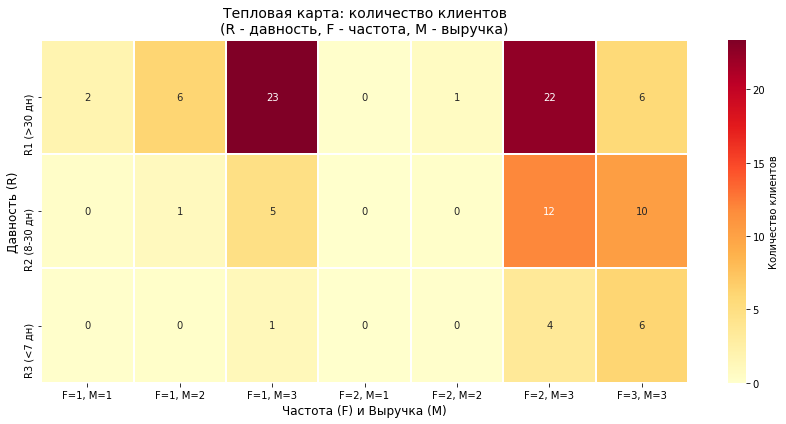

In [17]:
# Построим для наглядности тепловую карту

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_percent, annot=True, fmt='.0f', cmap='YlOrRd', 
            linewidths=1, linecolor='white',
            cbar_kws={'label': 'Количество клиентов'})

plt.title('Тепловая карта: количество клиентов\n(R - давность, F - частота, M - выручка)', 
          fontsize=14)
plt.xlabel('Частота (F) и Выручка (M)', fontsize=12)
plt.ylabel('Давность (R)', fontsize=12)
plt.tight_layout()
plt.show()


Зная критерии составления сегментов и имея тепловую карту можем провести некоторый анализ:

Есть 6 процентов клиентов, которые покупают много и часто - скорее всего они как раз делают большую часть выручки,
нужно поработать над их сохранением - например, карты лояльности

Очень мало людей покупало за прошедшую неделю - возможно, есть некоторые проблемы с удержанием старых пользователей, как
идею можно предложить делать ежемесячные или еженедельные розыгрыши или скидки, приуроченные к какому либо событию
Также около четверти клиентов делают заказы примерно несколько раз в месяц, их тоже нужно сохранить, как пример, работать
так же, как и с клиентами из сегмента 333

(В целом, наверно не так часто покупают в интернет-магазинах подарки, в связи с этим такая тенденция на тепловой карте имеет
место быть (возможно, следовало выбрать когорты по последнему заказу как 3 - до 2 недель, 2 - до 2 месяцев, тк не каждую
неделю и возможно не каждый месяц мы что-то кому-то покупаем в подарок))

Около 55 процентов приносили очень большой доход раньше, за послений месяц у них не было ни одно покупки, стоит рассмотреть
персональные скидки для них или отправить подборку товаров, похожих на их прошлые покупки, дляих обратного привлечения,
так как они составляют огромную часть выручки компании. Даже 10-5 процентов вернувшихся ощутимый прирост к выручке

Таким образом, следует усердно работать на удержание порядка 30 процентов пользователей, с остальными лучше работать на
привлечение

Также можно привлекать новую клиентуру при помощи каких-либо мероприятий или скидок новым клиентам
'''

# Проверка статистических гипотез

### Сравните доли возвратных и невозвратных клиентов  за второй и третий квартал 2019 года при помощи подходящего статистического теста


Гипотеза H0 - доли не различаются, H1 - разлчаются


Разделим клиентов на 4 группы:
1 - возвратные 2 квартал
2 - возвратные 3 квартал
3 - невозвратные 2 квартал
4 - возвратные 3 квартал

q2_data и q3_data использовались при расчете стики-факторов

In [19]:
# Срез данных за 2 и 3 квартал
q2_data = df[
    (df['entry_date'].dt.year == 2019) &
    (df['entry_date'].dt.quarter == 2) &
    (df['customer_id'] != 'undefined')
].copy()

q3_data = df[
    (df['entry_date'].dt.year == 2019) &
    (df['entry_date'].dt.quarter == 3) &
    (df['customer_id'] != 'undefined')
].copy()
q2_repeat = q2_data.groupby('customer_id')['order_id'].nunique()

q2_repeat_customers = q2_repeat[q2_repeat >= 2].index.tolist()
q2_non_repeat_customers = q2_repeat[q2_repeat == 1].index.tolist()

# Срез данных за 3 квартал
q3_repeat = q3_data.groupby('customer_id')['order_id'].nunique()

q3_repeat_customers = q3_repeat[q3_repeat >= 2].index.tolist()
q3_non_repeat_customers = q3_repeat[q3_repeat == 1].index.tolist()

# успех - доля возвратных, попытки - все клиенты
successes = [len(q2_repeat_customers), len(q3_repeat_customers)]
attempts = [
    len(q2_repeat_customers) + len(q2_non_repeat_customers),
    len(q3_repeat_customers) + len(q3_non_repeat_customers)
]

z_stat, p_value = proportions_ztest(count=successes, nobs=attempts, alternative='two-sided')
alpha = 0.05
print("Результаты z-теста для долей возвратных клиентов за 2 и  3 квартал")
print(f"z-statistic: {z_stat}, p-value: {p_value:.3f}")
if p_value < alpha:
    print("Отвергаем нулевую гипотезу: существует значимая разница между долями\n")
else:
    print("Не отвергаем нулевую гипотезу: значимой разницы между долями нет\n") 


Результаты z-теста для долей возвратных клиентов за 2 и  3 квартал
z-statistic: 0.2639206395175101, p-value: 0.792
Не отвергаем нулевую гипотезу: значимой разницы между долями нет




### Сравните средние чеки в странах с country_id, равному 3, 6 и 24.На основе статистических тестов сделайте вывод о том, отличаются ли средние чеки в этих странах или нет.

H0 - средние чеки не различаются, H1 - средние чеки различаются

Тк у нас 3 группы, то используем тест Манна-Уитни с множественными проверками


In [20]:
# Берем данные по странам
countries = [3, 6, 24]
data_by_country = {}


for country in countries:
    mask = (df['country_id'] == country) & (df['customer_id'] != 'undefined')
    country_data = df[mask]
    
    avg_checks = (country_data.groupby('customer_id')['revenue'].sum() / 
                  country_data.groupby('customer_id')['order_id'].nunique()).dropna()
    
    data_by_country[country] = avg_checks


alpha = 0.05
pairs = [(3, 6), (3, 24), (6, 24)]
bonferroni_alpha = alpha / len(pairs)

print("Результаты теста Манна-Уитни для проверки равенства средних чеков в странах")
for c1, c2 in pairs:
    stat, p_value = mannwhitneyu(data_by_country[c1], data_by_country[c2], alternative='two-sided')
    print(f"manwhitneyu: {stat}, p-value: {p_value:.5f}")
    if p_value < bonferroni_alpha:
        print("Отвергаем нулевую гипотезу: существует разница между средними чеками в странах", c1, "и", c2, "\n")
    else:
        print("Не отвергаем нулевую гипотезу: значимой разницы  между средними в странах", c1, "и", c2, "нет\n")
        


Результаты теста Манна-Уитни для проверки равенства средних чеков в странах
manwhitneyu: 1165.0, p-value: 0.85614
Не отвергаем нулевую гипотезу: значимой разницы  между средними в странах 3 и 6 нет

manwhitneyu: 139.0, p-value: 0.10680
Не отвергаем нулевую гипотезу: значимой разницы  между средними в странах 3 и 24 нет

manwhitneyu: 459.0, p-value: 0.22974
Не отвергаем нулевую гипотезу: значимой разницы  между средними в странах 6 и 24 нет



### Сравним среднее количество заказов на клиента за первый и второй квартал

Гипотезы: H0 - среднее количество заказов по кварталам не различается, H1 - среднее количество заказов 
по кварталам различается

Используем тест Манна-Уитни, тк он не требует от групп нормального распределения

In [21]:
q1 = df[(df['entry_date'].dt.year == 2019) & (df['entry_date'].dt.quarter == 1)
        & (df['customer_id'] != 'undefined')].groupby('customer_id')['order_id'].nunique()
q2 = df[(df['entry_date'].dt.year == 2019) & (df['entry_date'].dt.quarter == 2)
        & (df['customer_id'] != 'undefined')].groupby('customer_id')['order_id'].nunique()

alpha = 0.05
print("Результаты теста Манна-Уитни для проверки изменения выручки в зависимости от квартала")
stat, p_value = mannwhitneyu(q1, q2, alternative='two-sided')


print(f"\nMann-Whitney U = {stat}, p-value = {p_value:.3f}")
if p_value < alpha:
    print("Отвергаем нулевую гипотезу: существует значимая разница между средним количеством заказов в кварталах\n")
else:
    print("Не отвергаем нулевую гипотезу: значимой разницы между средним количеством заказов нет\n")

Результаты теста Манна-Уитни для проверки изменения выручки в зависимости от квартала

Mann-Whitney U = 1473880.0, p-value = 0.001
Отвергаем нулевую гипотезу: существует значимая разница между средним количеством заказов в кварталах



# Вывод


Был проанлизирован интернет-магазин "Подарочек", для этого были предобработаны данные и исключены сильные выбросы
для дальнейшего анализа. Были определены основные метрики
(лучшие страны (на одну из стран приходить 90 процентов всех заказов), лучшие кластеры),
был расчитан стики-фактор за 2 и 3 квартал - около 5%, что для интернет магазина является очень хорошим показателем.
Также были проанализированы дни без активности (возможно, сайт был недоступен в это время в связи с техническими работами).
Были составлены профили клиентов и проведена rfm-сегментация клиентов с их последующим анализом, были выявлены группы
клиентов для удержания и вовлечения, предложены стратегии по увелечению их лояльности и их возможной дальнейшей выручки
для бизнеса.
Также были проверены некоторые гипотезы  про средний чек. среднее количество заказов и вовлеченность клиентов - с их
результатами можете ознакомиться немного выше